# Quiz 3：CLIP Image Captioning（30 分）

**蘇芯儀 / Sharon0726**

本 Notebook 已執行並顯示 Colab T4 訓練保存的真實結果。訓練程式與推論程式完整附在同目錄；需要重訓請使用 `MMIP_Week5_Colab.ipynb`，本 Notebook 重跑只讀取結果，不重新訓練。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
R=Path('results')
assert R.exists(), 'Run from Week5 with results/ present.'
def read(name): return json.loads((R/name).read_text(encoding='utf-8'))
def show(name): display(Image(filename=str(R/'figures'/name)))
def source(name): display(Markdown('```python\n'+Path(name).read_text(encoding='utf-8')+'\n```'))


## 1. 沿用 Week4 資料（5 分）

完全相同 Flickr8k 切分、train-only 字典、五句參考與 test 順序。Week4 測試預測由固定 Git commit 保存原樣，未重挑樣本。

In [2]:
display(read('caption_data.json'))
s=pd.read_csv(R/'flickr_split.csv')
pd.testing.assert_frame_equal(s,pd.read_csv('baseline_week4/caption_split.csv'))
display(s.groupby('split').size())
print('PASS: exactly the Week4 image-level split.')

{'encoder': 'CLIP ViT-B/32 frozen image tower + visual projection (512 dimensions)',
 'encoder_revision': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268',
 'vocabulary': 'identical Week4 training-only vocabulary',
 'vocab_size': 6000,
 'max_length': 32,
 'counts': {'train': 6000, 'validation': 1000, 'test': 1091},
 'comparison': 'same split, references, tokenizer, vocabulary, GRU/LSTM architecture, epochs and greedy decoding; image encoder changed'}

split
test          1091
train         6000
validation    1000
dtype: int64

PASS: exactly the Week4 image-level split.


## 2. CLIP encoder + 文字 decoder（10 分）

CLIP ViT-B/32 影像塔及 visual projection 輸出 512 維；固定 encoder，訓練影像投影與 256 維 embedding / hidden GRU 或 LSTM。decoder 架構與 Week4 相同，CLIP text encoder 不參與文字生成。

In [3]:
source('caption_decoder.py')
display(read('features_clip.json'))

```python
import torch
from torch import nn

class CaptionModel(nn.Module):
    def __init__(self, vocab_size, kind='lstm', embedding=256, hidden=256):
        super().__init__()
        self.kind = kind
        self.embedding = nn.Embedding(vocab_size, embedding, padding_idx=0)
        self.h0 = nn.Linear(512, hidden)
        self.c0 = nn.Linear(512, hidden) if kind == 'lstm' else None
        self.recurrent = (nn.LSTM if kind == 'lstm' else nn.GRU)(embedding, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(hidden, vocab_size)

    def initial(self, features):
        h = torch.tanh(self.h0(features)).unsqueeze(0)
        return (h, torch.tanh(self.c0(features)).unsqueeze(0)) if self.kind == 'lstm' else h

    def forward(self, features, inputs):
        out, _ = self.recurrent(self.dropout(self.embedding(inputs)), self.initial(features))
        return self.head(self.dropout(out))

    @torch.inference_mode()
    def generate(self, features, max_length=32):
        state = self.initial(features)
        current = torch.full((len(features), 1), 2, dtype=torch.long, device=features.device)
        done = torch.zeros(len(features), dtype=torch.bool, device=features.device)
        outputs = []
        for _ in range(max_length - 1):
            out, state = self.recurrent(self.embedding(current), state)
            logits = self.head(out[:, -1])
            logits[:, [0, 1, 2]] = -torch.inf
            nxt = logits.argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, 3), nxt)
            outputs.append(nxt)
            done |= nxt.eq(3)
            current = nxt[:, None]
            if done.all():
                break
        return torch.stack(outputs, dim=1)



```

{'kind': 'clip',
 'dataset_revision': '81fc5f3a41274c80f17b0406426d57cac57ce6fb',
 'model_revision': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268',
 'transform': 'CLIPImageProcessor original',
 'shape': [8091, 512],
 'extraction_seconds': 95.35301198999969,
 'frozen': True}

## 3. 模型訓練與描述生成（5 分）

每張 train 圖展開五句 caption；teacher forcing、忽略 PAD 的 token cross-entropy，20 epochs、Adam lr=0.001、batch=128。依 validation token loss 選模型；test 從 BOS 自回歸 greedy decode 到 EOS，不讀取參考句。完整迴圈在 [quiz3_clip_caption.py](quiz3_clip_caption.py)。

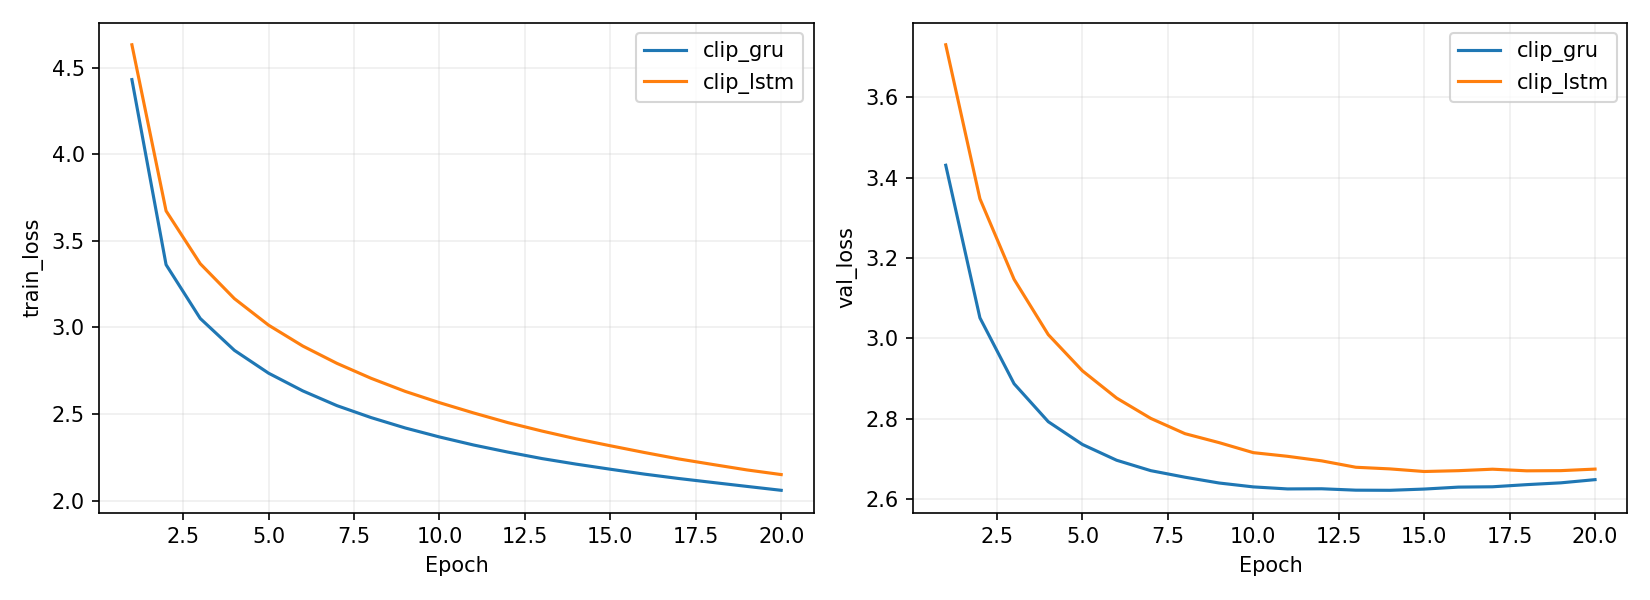

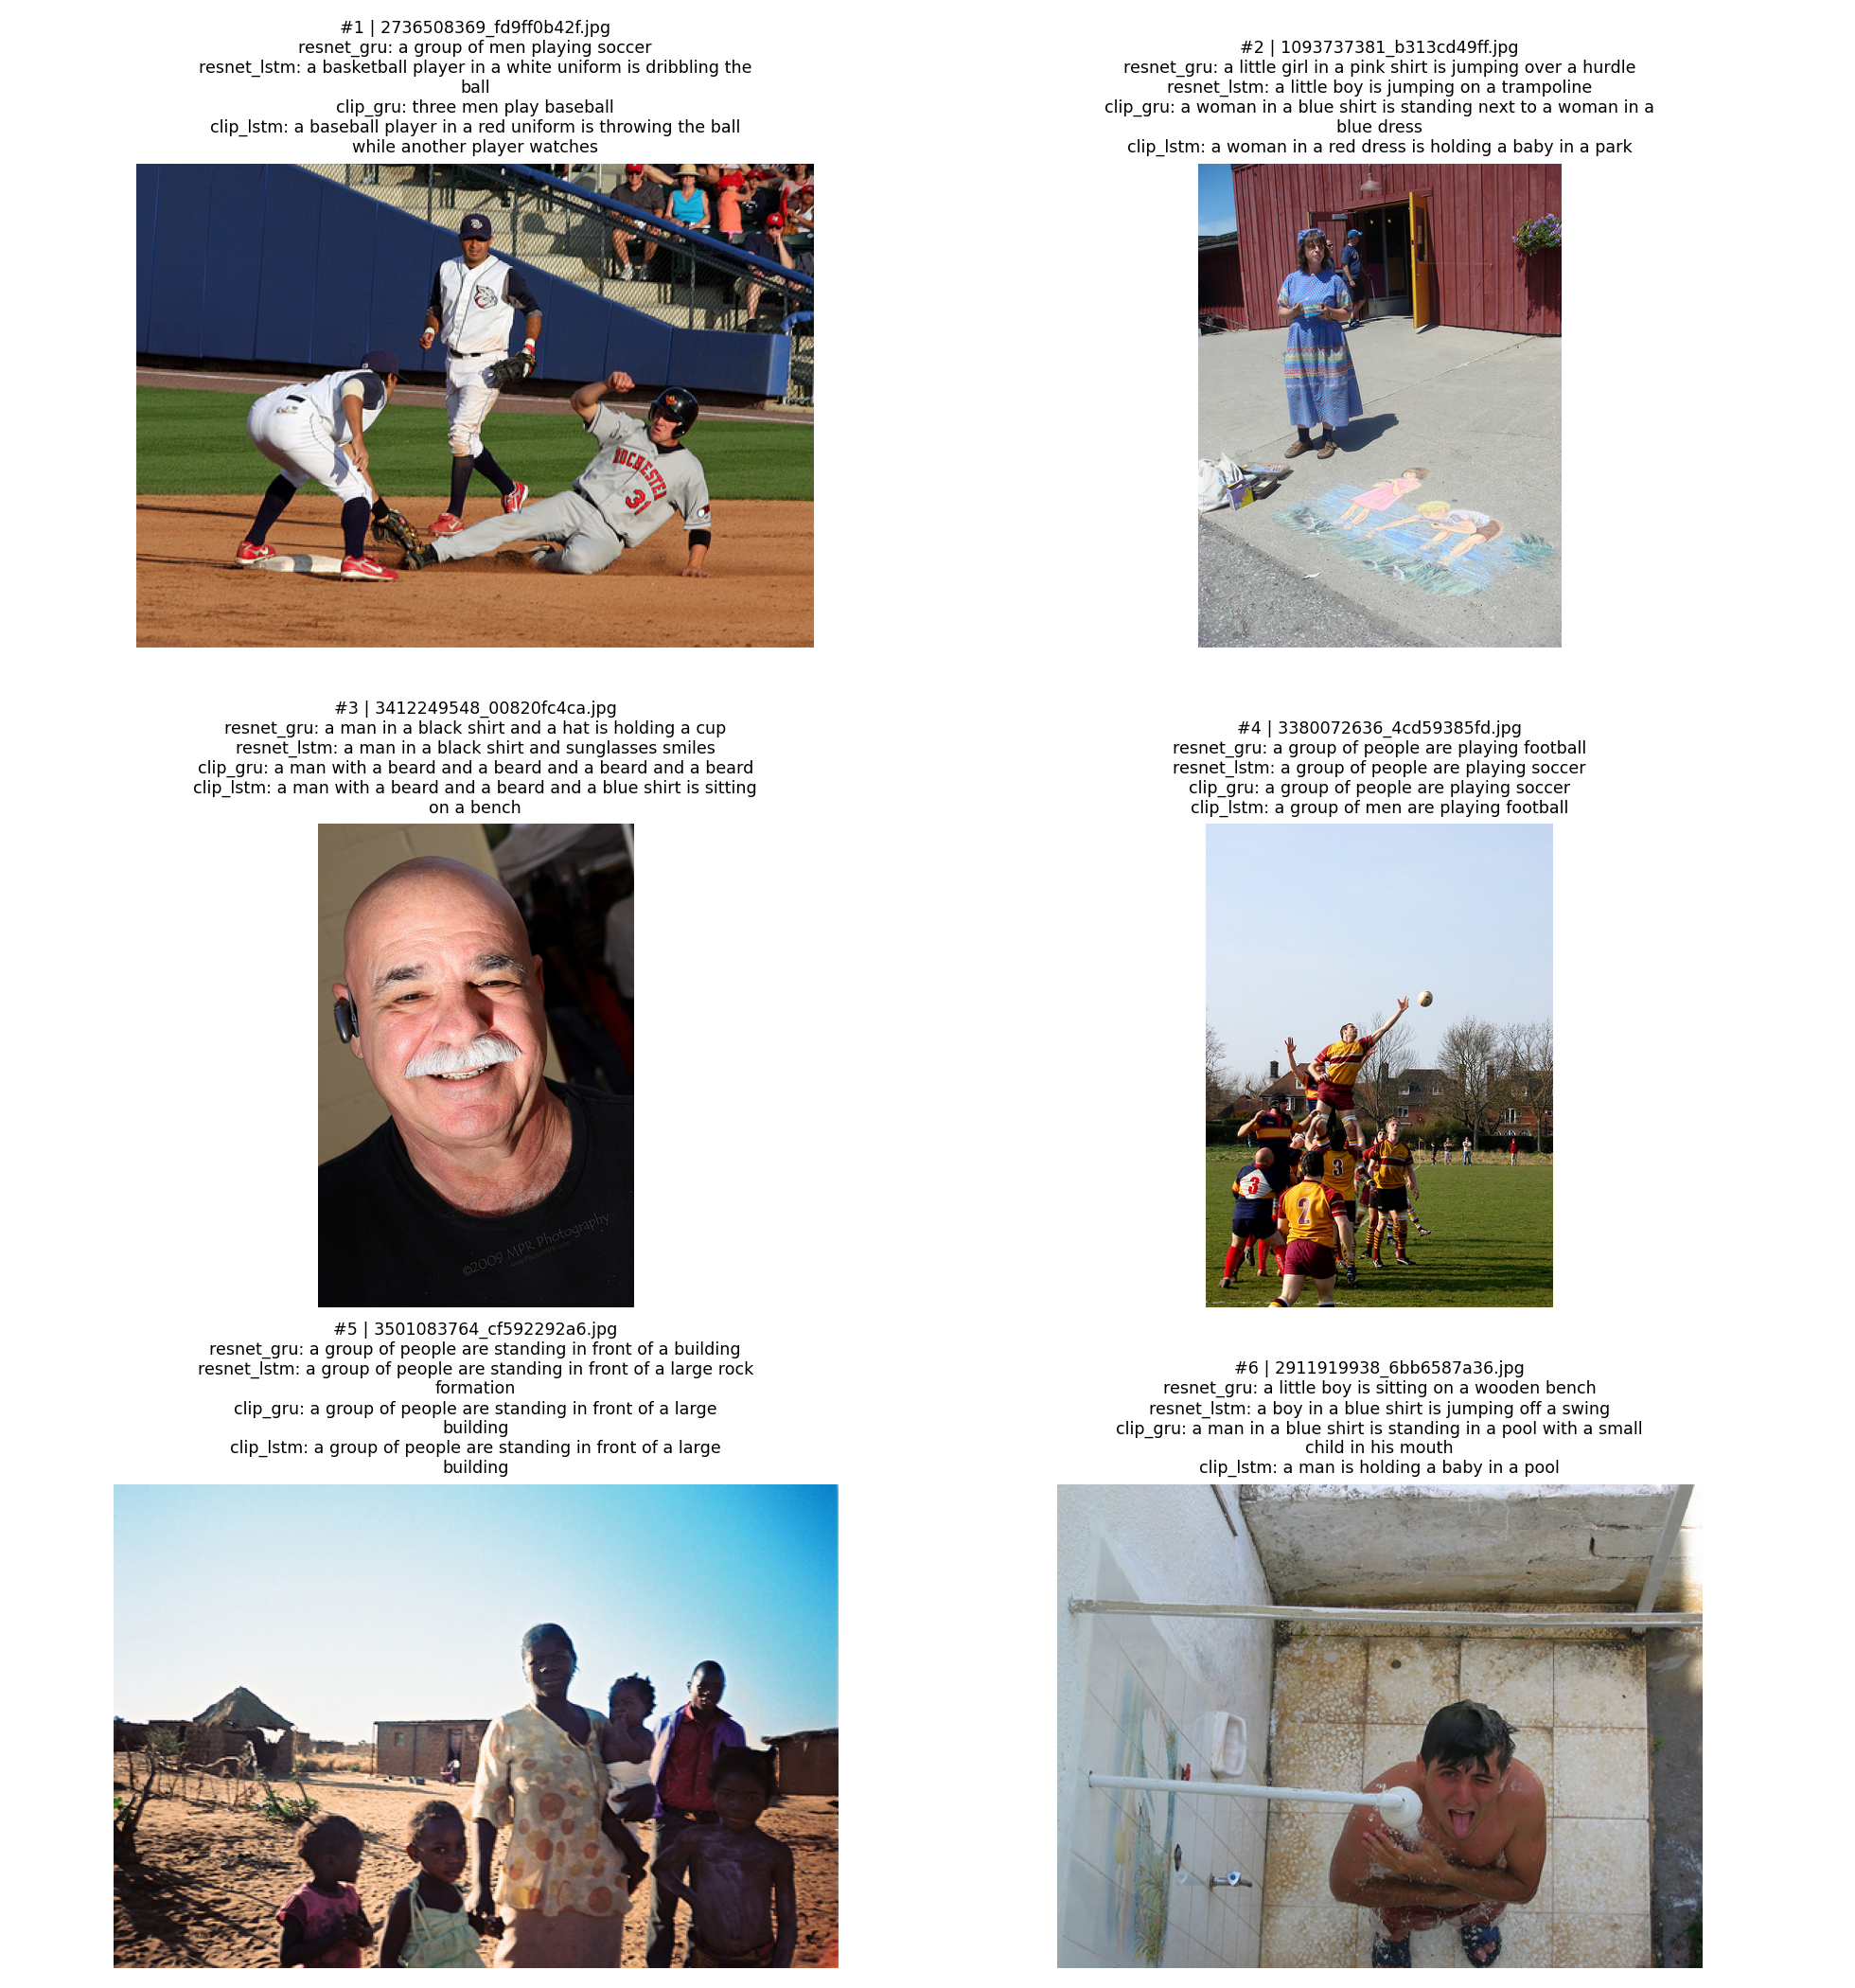

,filename,clip_gru,clip_lstm
0,2736508369_fd9ff0b42f.jpg,three men play baseball,a baseball player in a red uniform is throwing...
1,1093737381_b313cd49ff.jpg,a woman in a blue shirt is standing next to a ...,a woman in a red dress is holding a baby in a ...
2,3412249548_00820fc4ca.jpg,a man with a beard and a beard and a beard and...,a man with a beard and a beard and a blue shir...
3,3380072636_4cd59385fd.jpg,a group of people are playing soccer,a group of men are playing football
4,3501083764_cf592292a6.jpg,a group of people are standing in front of a l...,a group of people are standing in front of a l...
5,2911919938_6bb6587a36.jpg,a man in a blue shirt is standing in a pool wi...,a man is holding a baby in a pool


In [4]:
show('caption_learning.png')
show('caption_examples.png')
display(pd.DataFrame(read('caption_examples.json'))[['filename','clip_gru','clip_lstm']])

## 4. 與 Week4 比較 BLEU、BERTScore（10 分）

四個模型同 1091 張 test、五句參考。NLTK corpus BLEU-1/4 無 smoothing、沿用 regex tokenizer。BERTScore 為固定 revision 的 BERT-base-uncased 第 9 層、無 IDF、無 baseline rescaling；各圖在五參考中分別取最大 P/R/F，再對圖片平均。所有模型設定完全相同。

{'model': 'google-bert/bert-base-uncased',
 'revision': '86b5e0934494bd15c9632b12f734a8a67f723594',
 'num_layers': 9,
 'idf': False,
 'rescale_with_baseline': False,
 'use_fast_tokenizer': False,
 'batch_size': 32,
 'multiple_references': 'BERTScore 0.3.13 max across all five references for each P/R/F component, then mean over images',
 'hash': 'google-bert/bert-base-uncased_L9_no-idf_version=0.3.12(hug_trans=4.49.0)'}

,model,week,best_epoch,train_seconds,decoder_parameters,bleu1,bleu4,bertscore_precision,bertscore_recall,bertscore_f1,test_images
2,resnet_gru,4,NaN,NaN,NaN,0.537270,0.144649,0.688320,0.652106,0.663347,1091
3,resnet_lstm,4,NaN,NaN,NaN,0.508075,0.133642,0.684421,0.647263,0.658729,1091
0,clip_gru,5,14.0,95.538124,3604080.0,0.659576,0.240962,0.735627,0.691795,0.706075,1091
1,clip_lstm,5,15.0,100.762028,3866992.0,0.657797,0.233881,0.734249,0.691159,0.705133,1091


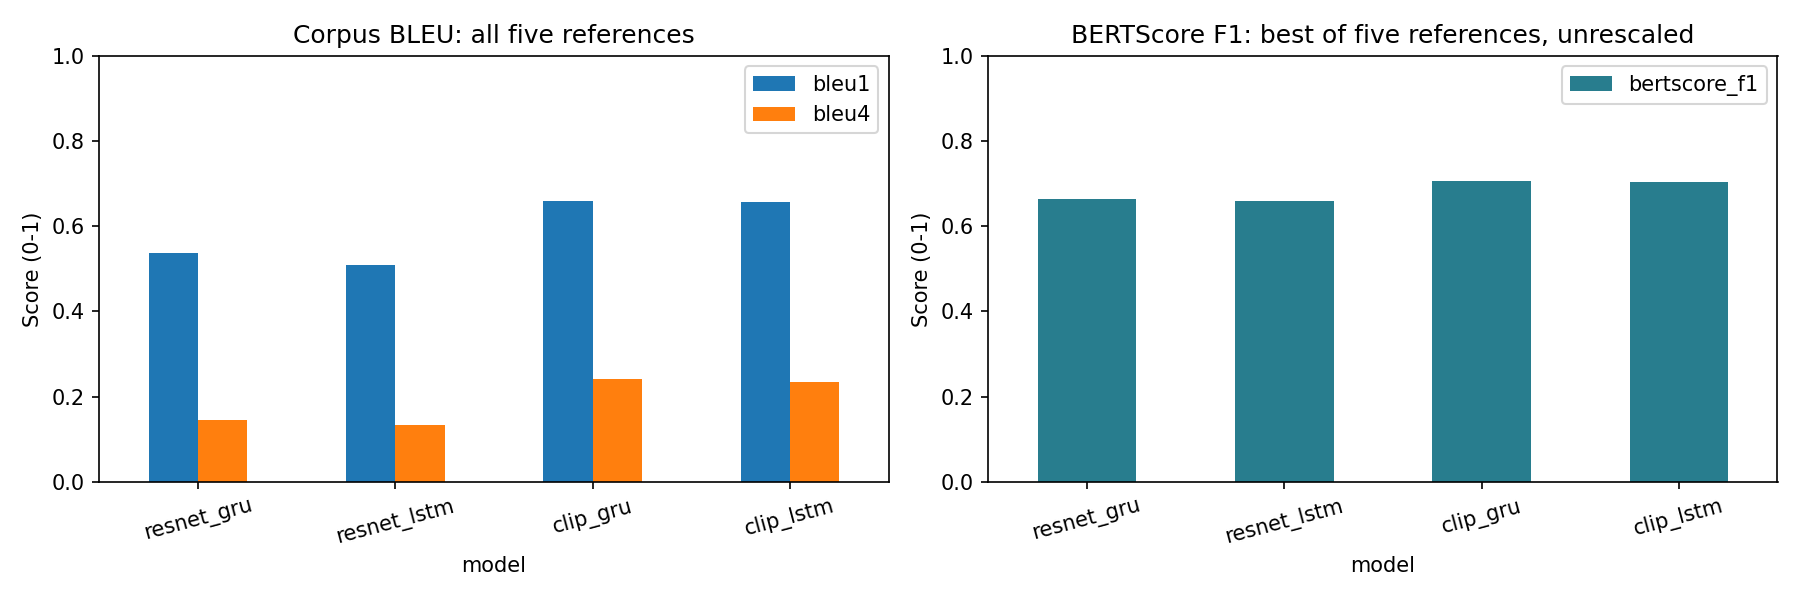

,decoder,mean_delta_bertscore_f1,paired_bootstrap_ci95_low,paired_bootstrap_ci95_high
0,gru,0.042728,0.038075,0.047507
1,lstm,0.046403,0.041660,0.050777


In [5]:
display(read('bertscore_settings.json'))
d=pd.read_csv(R/'caption_comparison.csv').sort_values(['week','model'])
display(d)
show('caption_comparison.png')
display(pd.read_csv(R/'caption_paired_comparison.csv'))

Paired bootstrap 2000 次只描述測試影像抽樣變異，不能當作多 seed 訓練變異。BLEU 看詞序重疊；BERTScore 看 token 語意相似，兩者都不直接驗證圖片內容。CLIP 預訓練規模與影像前處理也不同，無法排除與 Flickr8k 重疊。請搭配保留的錯誤描述觀察。

In [6]:
display(read('verification.json'))
display(read('environment.json'))
display(read('completed.json'))

{'passed': True,
 'checks': ['Retrieval partitions, qualified IDs, ranked labels, Hit@K/P@5/mAP@10, latency, backbone update',
  'Multimodal within-split pairing, per-input label balance, common test IDs, probability metrics',
  'Exact Week4 split/references, nonempty captions, corpus BLEU recomputation and BERTScore per-image mean',
  'Executed training source SHA-256 matches delivered source'],
 'bertscore_check': 'per-image output aggregation; no CPU rerun of contextual model'}

{'started_utc': '2026-10-12T04:39:09.188631+00:00',
 'python': '3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'device': 'cuda',
 'gpu': 'Tesla T4',
 'packages': {'torch': '2.11.0+cu130',
  'torchvision': '0.26.0+cu130',
  'datasets': '3.6.0',
  'timm': '1.0.15',
  'transformers': '4.49.0',
  'bert-score': '0.3.13',
  'nltk': '3.9.1',
  'numpy': '2.1.3',
  'pandas': '2.2.3',
  'scikit-learn': '1.6.1',
  'Pillow': '11.3.0'}}

{'training_complete': True,
 'completed_utc': '2026-10-12T04:55:28.739537+00:00'}

完整實驗解讀、比較限制與來源見 [REPORT.md](REPORT.md)。輸出的逐筆預測與 BERTScore CSV 可獨立查核。